# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі запускаємо локально через [Ollama](https://ollama.com) і звертаємося до нього звичайними HTTP-запитами.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.15


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

In [ ]:
QUESTION = "Запитання: Яка столиця Франції?" + "Відповідь:"

print(generate_raw(BASE_MODEL, QUESTION))

 Париж.


### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.2 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 566 | генерація: 5.0 с
--- міркування (1459 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package is 4 apples, and there are 2 packages. So that's 4 times 2, which is

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 2.1 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 668 | генерація: 6.3 с
--- міркування (1632 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" (which is the Russian letter for "r") appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Wait, is that the correct spelling? Let me confirm. In Ukrainian, "transformation" is "трансформація", but the word given here is "трансформер". So, "тра

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

In [ ]:
compare_thinking("""
Персонаж D&D має такі характеристики та екіпірування:

- Спритність: 18 (+4 до модифікатора).
- Зброя завдає від 6 до 12 одиниць фізичної шкоди.
- Рукавиці додають від 2 до 4 одиниць некротичної шкоди.

Персонаж атакує трьох ворогів:
1. Перший отримує мінімальну можливу шкоду від усіх джерел.
2. Другий отримує максимальну можливу шкоду від усіх джерел.
3. Третій отримує середнє значення шкоди від усіх джерел.

Модифікатор спритності додається лише до фізичної шкоди.

Обчисли шкоду для кожного ворога окремо.
Покажи розрахунки та загальну шкоду.
Не враховуй броню, опір та інші модифікатори.
""")

=== think=False | токенів: 777 | генерація: 6.8 с
--- відповідь:
Ось розрахунок шкоди, яку відповідний персонаж D&D віддасть кожному з трьох ворогів, з урахуванням усіх умов:

---

### Персонаж:
- **Спритність**: 18 (+4 до модифікатора)  
- **Зброя**: завдає від 6 до 12 одиниць фізичної шкоди  
- **Рукавиці**: додають від 2 до 4 одиниць некротичної шкоди

---

### Ворог 1: **Мінімальність шкоди**
- **Мінімальна шкода** = 6 (від 6 до 12, включно)
- **Спритність** додає +4 до фізичної шкоди
- **Фізична шкода** = 6 + 4 = **10**
- **Некротична шкода** = 0 (без рукавів)
- **Всього шкоди** = 10 (фізична) + 0 (некротична) = **10**

---

### Ворог 2: **Максимальна шкода**
- **Максимальна шкода** = 12
- **Спритність** додає +4
- **Фізична шкода** = 12 + 4 = **16**
- **Некротична шкода** = 0 (без рукавів)
- **Всього шкоди** = 16 (фізична) + 0 (некротична) = **16**

---

### Ворог 3: **Середнє значення шкоди**
- **Середнє значення** = (6 + 12) / 2 = **9**
- **Спритність** додає +4
- **Фізична шко

### Експеримент: розрахунок шкоди персонажа D&D

Для перевірки впливу режиму міркування було використано задачу з розрахунком бойової шкоди персонажа D&D.

Персонаж мав модифікатор спритності +4, зброю з фізичною шкодою 6–12 одиниць та рукавиці, які додавали 2–4 одиниці некротичної шкоди.

**Результати без міркування (think=False):**
- Мінімальна шкода: 10.
- Максимальна шкода: 16.
- Середня шкода: 13.

Модель врахувала фізичну шкоду зброї та модифікатор спритності, але проігнорувала додаткову некротичну шкоду від рукавиць.

**Результати з міркуванням (think=True):**
- Мінімальна шкода: 12.
- Максимальна шкода: 20.
- Середня шкода: 16.

У цьому режимі модель врахувала всі складові шкоди та правильно виконала обчислення.

**Висновок:**

У цьому експерименті режим міркування позитивно вплинув на результат. Без нього модель пропустила одну з умов задачі, через що всі три результати виявилися неправильними. З використанням міркування модель врахувала додаткову некротичну шкоду та отримала правильні відповіді.

Цей приклад демонструє, що режим міркування може бути корисним не лише для складних математичних обчислень, але й для уважного аналізу багатокомпонентних умов задачі.

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


In [ ]:
print("Compute Capability:", torch.cuda.get_device_capability())

Compute Capability: (7, 5)


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    # if name == "fp16":
    #     words = re.findall(r'\w+', PPL_TEXT["English"])
    #     random.Random(42).shuffle(words)
    #     random_text = " ".join(words)

    #     random_ppl = perplexity(model, random_text)

    #     print("Випадковий текст:", random_text)
    #     print("Перплексія випадкового тексту:", random_ppl)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

fp16: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int8: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,3.45,7.11,22.56,4.35,3.10,8.64,0.25
int8,2.04,2.98,14.32,4.45,3.11,9.13,0.25
int4,1.38,2.31,7.47,7.52,5.60,10.10,0.58
int2,1.03,1.96,7.36,438691.38,5951889.50,0.11,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

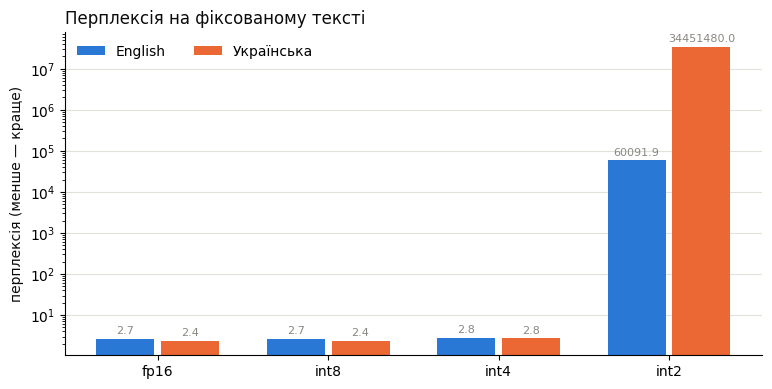

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

1. =
2. B
3. B
4. А
5. B


Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "=", 2: "B", 3: "B", 4: "A", 5: "B"}

In [ ]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,однаково
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,int4
2,Explain in three sentences why the sky is blue.,fp16,int4,int4
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,int4
4,Write a Python function that checks whether a ...,int4,fp16,fp16


fp16 краща: 1, int4 краща: 3, однаково: 1


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

#0.0 Відповіді на теоретичні питання
###1 У розділі 1.5 демо модель помиляється, рахуючи літеру «р» у слові «трансформер», — причому і без міркувань, і з ними. Поясніть, чому. Підтвердіть пояснення кодом.
Мовні моделі працюють із текстом, розбитим на токени, а не сприймають слово як послідовність окремих літер. Тому їм складно виконувати точні посимвольні операції, зокрема підрахунок повторень певної літери.

Без міркування: модель відповіла, що літера «р» трапляється 1 раз.

З міркуванням: відповіла що — 2 рази.

In [ ]:
word = "трансформер"
count = word.count("р")

print(f"Кількість літер «р»: {count}")

Кількість літер «р»: 3


###2 Як у розділі 2.4 демо змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?

Під час зменшення точності квантування від fp16 до int2 спостерігається значне погіршення якості моделі. Варіанти int8 та int4 зберігають відносно стабільні показники перплексії та метрик перекладу. Найбільший стрибок відбувається між int4 та int2: перплексія різко зростає, а показники chrF і BLEU падають майже до нуля. Це свідчить про те, що надмірне зменшення точності квантування призводить до суттєвої втрати здатності моделі генерувати якісний текст.

###3 Чи однаково зростає перплексія для англійської й української? Порівняйте з висновком зі слайду «Де може просідати якість при квантизації».

Перплексія для англійської та української зростає неоднаково. Для fp16 та int8 показники майже не змінюються, а при int4 перплексія української зростає з 2.4 до 2.8, тоді як англійської залишається майже на тому самому рівні. При int2 перплексія різко зростає для обох мов, але для української значно сильніше — до 34 451 480 проти 60 091.9 для англійської. Це узгоджується з висновком зі слайду «Де може просідати якість при квантизації»: менш представлені в навчальних даних мови можуть сильніше втрачати якість під час агресивного квантування.

###4 Чи збігається ваш вибір у сліпому порівнянні (розділ 2.5 демо) з тим, що показали автоматичні метрики? Чи помітили ви різницю там, де метрики майже не змінилися, — або навпаки?

У сліпому порівнянні int4 отримала перевагу в 3 випадках із 5, fp16 — в одному, ще в одному випадку якість відповідей була однаковою. Це частково збігається з автоматичними метриками, які показали, що int4 зберігає близьку до fp16 якість. Отже, попри нижчу точність, int4 у більшості перевірених завдань не поступалася fp16 за суб'єктивною оцінкою.

###5 Знайдіть у таблиці перекладів (розділ 2.4 демо) правильний переклад, який відрізняється від еталона словами. Як на нього реагують BLEU і chrF?

У таблиці є приклад, коли переклад «Зустріч була перенесена на четвер, о 15 годині» правильно передає зміст оригіналу, але відрізняється від еталонного перекладу формулюванням. Метрика BLEU може знизити оцінку через відмінності у словах та їх послідовності, тоді як chrF враховує схожість на рівні символів і може краще оцінити такий варіант. Це показує, що автоматичні метрики не завжди об'єктивно оцінюють якість перекладу, оскільки можуть не враховувати синоніми та альтернативні правильні формулювання.

###6 У скільки разів зменшилася памʼять у таблиці розділу 2.4 демо і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?

Зменшення не є рівно дво-, чотири- чи восьмикратним через додаткові витрати пам'яті на метадані квантування, масштаби та службові параметри. Швидкість генерації також не зросла: якщо fp16 забезпечувала 16,13 токенів/с, то int8 — 6,06, int4 — 2,98, а int2 — 3,03 токенів/с. Квантування зменшило використання пам'яті, але водночас уповільнило генерацію.

###7 Чому Base-модель у розділі 1.2 відповідає на питання новими питаннями? Сформулюйте промпт так, щоб Base-модель усе ж дала відповідь. Наведіть код і результат.

Base-модель навчена переважно передбачати наступні токени тексту, а не безпосередньо відповідати на запитання користувача. Вона не завжди розуміє інструкції як Chat-модель, тому може продовжувати запитання або формулювати зустрічні питання замість відповіді.

`QUESTION = "Запитання: Яка столиця Франції?" + "Відповідь:"`

`print(generate_raw(BASE_MODEL, QUESTION))`

###8 Скільки токенів і часу забрали міркування в розділі 1.4 порівняно з відповіддю без міркувань? Чому модель міркує англійською, хоча питання українською?

У режимі міркування модель використала 668 токенів замість 227, тобто на 441 токен більше. Час генерації збільшився з 2,1 до 6,3 секунди.

Модель міркує англійською, оскільки англійська мова широко представлена в навчальних даних і може бути основною мовою внутрішнього процесу міркування. При цьому остаточну відповідь вона сформувала українською.

###9 Знайдіть задачу, на якій режим міркування дає правильну відповідь, а без нього модель помиляється. Наведіть промпт і обидві відповіді.

Згадано вище: Задача D&D

###10 У функціях generate_raw і chat (розділ 1.1) стоять temperature: 0 і seed: 1. Навіщо?

У функціях generate_raw і chat параметри temperature: 0 та seed: 1 використовуються для забезпечення стабільності результатів генерації. temperature: 0 мінімізує випадковість під час вибору наступних токенів, а seed: 1 задає початкове значення генератора випадкових чисел. Це дозволяє зменшити відмінності між повторними запусками та об'єктивніше порівнювати результати моделі з міркуванням і без нього.

###11 Чому в секції 2 використовуємо fp16, а не bf16? Що показує torch.cuda.get_device_capability() на T4 і як це з цим повʼязано?

У секції 2 використовується fp16 замість bf16, оскільки відеокарта Tesla T4 не має апаратної підтримки BF16 на потрібному рівні. FP16 сумісний із цією відеокартою та дозволяє виконувати обчислення на GPU.

Команда torch.cuda.get_device_capability() повертає обчислювальні можливості відеокарти. Для Tesla T4 результат — (7, 5), тобто Compute Capability 7.5. Це означає, що відеокарта належить до архітектури Turing, тоді як повноцінна апаратна підтримка BF16 з'явилася в новіших архітектурах, починаючи з Ampere (8.0).

###12 Скільки параметрів у моделі з розділу 2.1 і скільки памʼяті має займати її fp16-версія за формулою з лекції? Порівняйте з «памʼяттю моделі» в таблиці розділу 2.4.

Модель Qwen3-4B-Instruct-2507 містить приблизно 4 мільярди параметрів. Оскільки один параметр у форматі fp16 займає 2 байти, теоретичний обсяг пам'яті становить близько 8 GB. У таблиці експерименту фактичне значення дорівнює 8,04 GB, що майже збігається з розрахунковим результатом.


###13 Що таке перплексія (розділ 2.2) і чому її не можна порівнювати між англійською й українською? Порахуйте перплексію fp16-моделі на випадковому наборі слів замість осмисленого тексту й поясніть результат.

Перплексія (PPL) показує, наскільки добре модель передбачає наступний токен. Чим менше значення, тим краще модель прогнозує текст.

Англійську й українську не можна безпосередньо порівнювати через відмінності токенізації: одне й те саме за змістом речення може розбиватися на різну кількість токенів.

Перплексія випадкового тексту становить 322.83, тоді як для осмисленого англійського тексту — 2.67. Значне зростання показника свідчить про те, що моделі набагато складніше передбачати наступні токени у випадковій послідовності слів. Це підтверджує залежність перплексії від змісту та структури вхідного тексту.

###14 Чому «пік VRAM» у таблиці розділу 2.4 більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?

Пік VRAM більший за пам'ять моделі, оскільки під час генерації відеопам'ять використовується не лише для зберігання ваг, а й для проміжних обчислень. Додаткову пам'ять займають KV-cache, активації нейронної мережі, тимчасові буфери та службові ресурси CUDA.

Пам'ять моделі — це обсяг пам'яті для зберігання ваг, а пік VRAM — максимальний обсяг відеопам'яті, використаний під час роботи моделі.

###15 Скільки разів у сліпому порівнянні (розділ 2.5) ви обрали fp16, int4 чи «однаково»? Наскільки впевнено можна робити висновки з 5 порівнянь і скільки їх знадобилося б для надійного висновку?

У 5 сліпих порівняннях fp16 отримала перевагу 1 раз, int4 — 3 рази, ще 1 раз результати були однаковими. Це свідчить про можливу перевагу int4, проте вибірки недостатньо для надійного висновку.
Для кращого розуміння бажано провести вибірку мінімум зі 100 різними за структурою завданнями.

###16 Як саме «ламається» модель у int2 (розділ 2.6)? Опишіть типові помилки у відповідях. Чи помітні їхні ознаки вже в int4?

У режимі int2 модель демонструє значну деградацію якості: відповіді перетворюються на випадкові комбінації слів і токенів, втрачають логічну структуру та зміст. У режимі int4 помітних помилок немає, хоча відповіді стають менш розгорнутими, зберігаючи основний сенс.

###17 Повторіть секцію 2 з меншою моделлю (наприклад, Qwen/Qwen3-1.7B). Чи сильніше квантизація бʼє по меншій моделі? Порівняйте перплексію й chrF з результатами для 4B.

Результати показують, що квантизація сильніше впливає на меншу модель Qwen3-1.7B, особливо в режимі int4.
- Перплексія: у 4B при переході з fp16 на int4 зростає з 2.67 до 2.81 (English), а в 1.7B — з 4.35 до 7.52. Для української аналогічно: 2.40 → 2.76 у 4B та 3.10 → 5.60 у 1.7B.
- chrF: у 4B показник майже не змінюється (55.22 → 55.34), а в 1.7B зростає з 8.64 до 10.10. Проте це не свідчить про покращення перекладу: початковий результат малої моделі вже дуже низький.
- int2: обидві моделі демонструють критичне погіршення якості, про що свідчить різке зростання перплексії.

###18 Поясніть принцип параметру OLLAMA_NUM_PARALLEL в ollama з демо?
OLLAMA_NUM_PARALLEL визначає максимальну кількість запитів, які Ollama може обробляти одночасно для однієї моделі. Збільшення значення дозволяє обслуговувати декількох користувачів паралельно, але збільшує потребу в оперативній пам'яті або VRAM.

###19 Чому майже всі сучасні моделі зберігаються в bf16?

Сучасні моделі переважно зберігаються у форматі BF16, оскільки він забезпечує більший діапазон числових значень порівняно з FP16, що зменшує ризик переповнення та втрати точності під час обчислень. При цьому BF16 займає лише 2 байти на параметр, як і FP16, що дозволяє економити пам'ять без значної втрати стабільності обчислень.

###20 Для чого всі рантайми моделей слідують протоколу OpenAI? Як це повʼязано з ChatGPT?

OpenAI API став поширеним стандартом взаємодії з мовними моделями. Його підтримка дозволяє різним рантаймам використовувати однаковий формат запитів і відповідей, спрощуючи інтеграцію моделей у програми.

#1.8. Мій звіт:
##Залізо:

Процесор: Intel Core i7-14650HX
Оперативна пам'ять: 16 ГБ (15,6 ГБ доступно)
Відеокарта: NVIDIA GeForce RTX 5060 Laptop GPU
VRAM: 8 ГБ

##Розрахунок:
###1 Пропускна здатність пам'яті
Спочатку визначимо, наскільки швидко відеокарта та процесор можуть зчитувати ваги моделі.

####Оперативна пам'ять (RAM)

Процесор підтримує DDR5-5600. Оскільки встановлена одна планка пам'яті, використовуємо одноканальну конфігурацію.

B = 5600 * 8 = 44800 МБ/с

Отже,  пропускна здатність RAM: 44,8 ГБ

####Відеопам'ять (VRAM)

RTX 5060 Laptop використовує GDDR7 із 128-бітною шиною пам'яті. Для цієї конфігурації заявлена пропускна здатність становить 384 ГБ/с.

Таким чином, пропускна здатність відеопам'яті приблизно у 8,6 раза більша за пропускну здатність оперативної пам'яті.

###2 Розрахунок доступної пам'яті
Загальний обсяг VRAM становить 8 ГБ.
- 2 ГБ — резерв відеопам'яті для інших процесів та непередбачених витрат.
- 6 ГБ — максимальний бюджет для моделі, KV-кешу та рантайму.

###3 Очікувана швидкість генерації:
Для оцінки швидкості генерації використаємо пропускну здатність відеопам'яті та розмір обраної моделі.
Згідно з даними Ollama, модель gemma3:4b-it-q8_0 займає приблизно 5 ГБ пам'яті.

Оскільки під час генерації модель повинна зчитувати свої ваги з пам'яті, оцінимо теоретичну швидкість:
V = B / S   
де:
- B — пропускна здатність VRAM (384 ГБ/с);
- S — розмір моделі (5 ГБ)
V = 384 / 5 = 76,8 токенів/c.  
Отже, очікувана теоретична швидкість генерації становить приблизно 76,8 токенів/с.
##Обрана модель, квантизація й рантайм і чому:

З огляду на характеристики обладнання, зокрема відеокарту NVIDIA GeForce RTX 5060 Laptop GPU із 8 ГБ VRAM, було вирішено використовувати модель класу 4B. Такий вибір дозволить забезпечити стабільнішу роботу та залишити достатньо відеопам’яті для потреб середовища виконання.

Для початкового запуску обрано модель Gemma 3 4B у форматі Q8_0 (8-бітна квантизація). Вона потребує менше пам’яті, ніж версії з повною 16-бітною точністю, водночас зберігаючи вищу точність ваг порівняно з 4-бітною квантизацією.

Під час оптимізації планується перейти на ту саму модель у форматі Q4_K_M (4-бітна квантизація). Це дозволить порівняти швидкість генерації та якість відповідей за різного рівня квантизації, не змінюючи саму модель. Для запуску й тестування обох варіантів використовуватиметься середовище Ollama.

##Вимірювання до оптимізації:

Під час першого тестування моделі Gemma 3 4B у форматі Q8_0 було використано власний набір із 10 промптів за тематикою Baldur's Gate 3. Тестування проводилося з різною кількістю одночасних клієнтів: 1, 2 та 4. У всіх трьох запусках помилок не зафіксовано.

Швидкість генерації для користувача становила 70,6–70,9 токена/с, а загальна пропускна здатність (Throughput) — 69,4–69,7 токена/с. Час очікування першого токена (TTFT p50) збільшувався зі зростанням кількості клієнтів: від 0,07 с для одного клієнта до 8,56 с для чотирьох.

**Якісна оцінка відповідей.**

Модель надає зрозумілі та загалом правильні відповіді на поставлені запитання. Водночас відповіді іноді мають надто загальний характер і не завжди містять достатньо конкретики. Також під час формування окремих речень помітні граматичні помилки, зокрема неправильне відмінювання слів, що іноді призводить до часткової втрати змісту. Загалом модель справляється з поставленими завданнями, проте якість формулювання відповідей потребує покращення.

##Порівння з очікуваннями

За результатами розрахунків пропускної здатності відеопам'яті та розміру моделі очікувана швидкість генерації становила приблизно 76,8 токенів/с. Під час тестування було отримано 70,9 токенів/с при одному одночасному користувачі. Виміряний результат загалом відповідає теоретичному прогнозу.

При збільшенні кількості одночасних користувачів швидкість генерації залишалася приблизно на тому самому рівні, проте час очікування першого токена (TTFT) суттєво зростав: з 0,071 с для одного користувача до 8,558 с для чотирьох. Це свідчить про зростання навантаження та конкуренцію запитів за ресурси системи.

##Оптимізація і вимірювання після:

На етапі оптимізації було вирішено використати ту саму модель Gemma 3 4B, але з форматом квантизації Q4_K_M замість Q8_0.

Після заміни квантизації було повторно проведено тестування на тому самому наборі з 10 промптів за тематикою Baldur's Gate 3. Умови вимірювання залишилися незмінними: використовувалися 1, 2 та 4 одночасні клієнти. У всіх трьох запусках помилок не зафіксовано.

Швидкість генерації для користувача становила 101,9–103,4 токена/с, а загальна пропускна здатність (Throughput) — 99–100,7 токена/с. Показники TTFT також покращилися: для одного клієнта медіанний час очікування першого токена становив 0,06 с, а для чотирьох клієнтів — 5,78 с.

**Якісна оцінка відповідей.**

Після переходу на Q4_K_M помітного погіршення якості відповідей не виявлено. Модель, як і під час першого запуску, надає зрозумілі та читабельні відповіді, правильно виконує більшість поставлених завдань. Водночас залишаються незначні граматичні та формулювальні помилки, проте вони не перешкоджають розумінню змісту.

##Застосунок — що робить і як працює, параметри генерації: ...

### Застосунок — BG3 Companion

**Призначення та функціональність.**

BG3 Companion — це локальний AI-асистент, призначений для допомоги гравцям у Baldur’s Gate 3. Основна мета застосунку — надавати практичні поради щодо створення персонажів, вибору класів і підкласів, розвитку характеристик, підбору спорядження та особливостей ігрового процесу.

На відміну від звичайного помічника з Dungeons & Dragons, застосунок орієнтований саме на механіки Baldur’s Gate 3. Він повинен враховувати відмінності між правилами настільної D&D та їх реалізацією у відеогрі.

Користувач може звертатися до асистента природною мовою, описувати бажаний стиль проходження або ставити конкретні запитання. Наприклад, гравець може попросити допомогти створити персонажа-асасина. У відповідь асистент пояснить, який клас потрібно обрати, на якому рівні відкривається відповідний підклас, які характеристики варто розвивати, які особливості має цей стиль гри та на що звертати увагу під час проходження.

Також передбачено надання рекомендацій без сюжетних спойлерів. Асистент не повинен розкривати сюжетні повороти, долі персонажів або майбутні події гри.

**Принцип роботи.**

Застосунок використовуватиме локальну модель Gemma 3 4B Q4_K_M, запущену через Ollama з використанням OpenAI-сумісного API.

Після введення запиту користувачем застосунок передаватиме його разом із системною інструкцією до локальної моделі. Системна інструкція визначатиме роль асистента, обмежуватиме тематику відповідей механіками Baldur’s Gate 3 та вимагатиме уникати сюжетних спойлерів. Отримана відповідь відображатиметься в інтерфейсі чату.

**Параметри генерації.**

- **Temperature: 0.3.** Обране значення дозволяє формувати природні та зрозумілі відповіді, зменшуючи надмірну варіативність і вигадування фактів.
- **Максимальна кількість токенів відповіді: 1200.** Цього достатньо для розгорнутої ігрової поради з поясненнями та рекомендаціями, але обмеження не дозволяє моделі генерувати надмірно довгі відповіді.
- **Довжина контексту: 4096 токенів.** Обрана з урахуванням можливостей обладнання та розміру моделі. Цього має вистачити для системної інструкції, поточного запиту й декількох попередніх повідомлень діалогу.


##Тестові сценарії й результати:
- Скільки основних характеристик у BG3?
BG3 Companion
У Baldur's Gate 3 є шість основних характеристик: Сила, Спритність, Витривалість, Інтелект, Мудрість та Харизма.
Джерело: BG3 Wiki - https://bg3.wiki/wiki/Abilities
- Як стати Клятвопорушником?
Стати Клятвопорушником у Baldur’s Gate 3 – це процес, що виникає внаслідок порушення вашої обраної клятви Паладина. Ось як це відбувається:

1.  **Вибір клятви:** Спочатку вам потрібно обрати клятву для свого Паладина на початку гри. Важливо пам’ятати, що Клятвопорушником стати можна лише після того, як ви обрали одну з клятв.
2.  **Порушення клятви:** Ключовим моментом є здійснення дій, які суперечать вашій клятві. Це може бути будь-яка дія, яка суперечить принципам, які ви обіцяли дотримуватися. Наприклад:
    *   **Клятва відданості (Oath of Devotion):** Вбив невинної людини, що суперечить захисту невинних.
    *   **Клятва помсти (Oath of Vengeance):** Навмисне вбивство людини, яка не заслуговує на смерть, щоб помститися.
    *   **Клятва корони (Oath of the Crown):** Зрадити союзника або підставити союзника заради власної вигоди.
3.  **Відкриття підкласу:** Після того, як ви порушили клятву, ви отримаєте можливість обрати підклас Клятвопорушника. Це відбудеться під час діалогу з персонажем, який допоможе вам зрозуміти, що сталося.
4.  **Вплив на сюжет:** Ставши Клятвопорушником, ви відкриєте для себе новий шлях у сюжеті, який буде зосереджений на наслідках ваших дій та моральних дилемах.

**Важливо:** Клятвопорушник – це не просто підклас, це результат ваших рішень. Ваші дії визначають вашу долю у грі.

Джерело: BG3 Wiki - https://bg3.wiki/wiki/Oathbreaker
##Висновок:
Програма має базове розуміння класів гри Baldur’s Gate 3 та здатна надавати загальні поради й рекомендації щодо вибору класу та розвитку персонажа. Також вона може адаптуватися до запитань користувача, формуючи відповіді, які іноді містять вигадані факти, схожі на реальні. Водночас такі відповіді переважно не виходять за межі загального розуміння правил D&D, на яких базується Baldur’s Gate 3, тому частина згенерованої інформації може бути правильною, хоча її достовірність не гарантована. Для підвищення точності та повноти відповідей необхідно розширити локальний довідник, додавши детальніші відомості про класи, підкласи та їхні особливості.
